In [1]:
import json
import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import optuna
import time
import xgboost as xgb

from catboost import CatBoostRegressor
from scipy.stats import loguniform, randint, uniform
from sklearn.cluster import KMeans
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import mean_absolute_error, r2_score, median_absolute_error, silhouette_score, homogeneity_score, completeness_score, adjusted_rand_score
from sklearn.model_selection import RandomizedSearchCV, GridSearchCV, TimeSeriesSplit, ParameterGrid
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.svm import SVR

pd.set_option('display.max_columns', 100)
optuna.logging.set_verbosity(optuna.logging.WARNING)
RANDOM_STATE = 42

In [2]:
JOBLOG = '/kaggle/input/datasets/poorvie05/param-2025-data/JobLog_Year_2025_time_fields_added.xlsx'      # <- your path

w = pd.read_excel(JOBLOG, header=1, dtype=str)           # row 0 is 'Column1..Column25', the real header is row 1
for c in ['Submit', 'Start', 'End']:
    w[c] = pd.to_datetime(w[c], format='%Y-%m-%dT%H:%M:%S', errors='coerce')   # 'Unknown' -> NaT
for c in ['TimelimitRaw', 'ElapsedRaw', 'AllocCPUS', 'AllocNodes']:
    w[c] = pd.to_numeric(w[c], errors='coerce')
w = w[w['Submit'].notna()].reset_index(drop=True)
w['COBALT_JOBID'] = np.arange(1, len(w) + 1, dtype='int64')    # JobID is reused (same id, different users/dates) -> own unique id

good = ((w['State'] == 'COMPLETED') & (w['ExitCode'] == '0:0') & (w['AllocNodes'] > 0) & (w['AllocCPUS'] > 0)
        & (w['ElapsedRaw'] > 0) & (w['TimelimitRaw'] < 1e7) & w['Start'].notna() & w['End'].notna())
ok = w[good]
fam = ok['JobName'].str.lower().str.replace(r'[\d_\.\-\s]+', '', regex=True)       # 'GBR500','GBR1000' -> 'gbr'

# job table keeps ALL jobs (the co-scheduling section needs every running job); only 'good' ones count as successful
pd.DataFrame({
    'MACHINE_NAME': 'slurm', 'COBALT_JOBID': w['COBALT_JOBID'], 'JOB_NAME': w['JobID'] + '|' + w['JobName'],
    'EXIT_STATUS': np.where(good, 0, 1), 'EXIT_CODE': np.where(good, 0, 1),
    'QUEUED_TIMESTAMP': w['Submit'], 'START_TIMESTAMP': w['Start'], 'END_TIMESTAMP': w['End'],
    'USERNAME_GENID': pd.factorize(w['User'])[0], 'PROJECT_NAME_GENID': pd.factorize(w['JobName'])[0],
    'ALLOCATION_AWARD_CATEGORY': 'na', 'SCIENCE_FIELD_SHORT': 'na', 'MODE': 'na', 'QUEUE_NAME': w['Partition'],
    'WALLTIME_SECONDS': w['TimelimitRaw'] * 60.0, 'NODES_REQUESTED': w['AllocNodes'], 'CORES_REQUESTED': w['AllocCPUS'],
    'REQUESTED_CORE_HOURS': w['AllocCPUS'] * w['TimelimitRaw'] / 60.0, 'RUNTIME_SECONDS': w['ElapsedRaw'],
}).to_csv('/kaggle/working/jobcomp_slurm.csv', index=False)
pd.DataFrame({'COBALT_JOBID': ok['COBALT_JOBID'], 'RUN_TIME': ok['ElapsedRaw'],
              'EXE_NAME_GENID': pd.factorize(fam)[0], 'USER_ID': pd.factorize(ok['User'])[0]}
             ).to_csv('/kaggle/working/darshan_slurm.csv', index=False)
print(len(w), 'jobs ->', len(ok), 'usable successful')

91020 jobs -> 51801 usable successful


In [3]:
# CHOOSE THE SYSTEM: comment out TWO of these three blocks
# --- THETA ---
# darshan_path = "/kaggle/input/datasets/poorvie05/2023-data/ANL-ALCF-DARSHAN-THETA_20230101_20231231.csv"
# jobcomp_path = "/kaggle/input/datasets/poorvie05/2023-data/ANL-ALCF-DJC-THETA_20230101_20231231.csv"
# MACHINE = 'theta'

# --- POLARIS ---
darshan_path = "/kaggle/input/datasets/poorvie05/polaris-2025-data/features_coarse.csv"
jobcomp_path = "/kaggle/input/datasets/poorvie05/polaris-2025-data/ANL-ALCF-DJC-POLARIS_20250101_20251231.csv"
MACHINE = 'polaris'

# --- SLURM ---
# darshan_path = "/kaggle/working/darshan_slurm.csv"
# jobcomp_path = "/kaggle/working/jobcomp_slurm.csv"
# MACHINE = 'slurm'

darshan = pd.read_csv(darshan_path)
jobcomp = pd.read_csv(jobcomp_path, low_memory=False)
jobcomp_theta = jobcomp[jobcomp['MACHINE_NAME'].str.lower() == MACHINE].copy()

# ---- Polaris differences, handled automatically (these steps do nothing for the Theta files) ----
# 1) Polaris job table: COBALT_JOBID is 0 for every row; the real id is the number in JOB_NAME ("3123554.polaris")
if (jobcomp_theta['COBALT_JOBID'] == 0).all():
    jobcomp_theta['COBALT_JOBID'] = pd.to_numeric(jobcomp_theta['JOB_NAME'].str.extract(r'^(\d+)')[0]).astype('int64')
    jobcomp_theta = jobcomp_theta.drop_duplicates('COBALT_JOBID', keep=False)   # drop ambiguous repeated ids

# 2) Polaris Darshan summary (features_coarse.csv): different column names, no STDIO counters, no executable name
_time_cols = [f'TOTAL_{m}_F_{k}_TIME' for m in ('POSIX', 'MPIIO', 'STDIO') for k in ('READ', 'WRITE', 'META')]
darshan = darshan.rename(columns={'job_id': 'COBALT_JOBID', 'RUNTIME': 'RUN_TIME'} if 'job_id' in darshan.columns else {})
darshan = darshan.rename(columns={c[6:]: c for c in _time_cols if c[6:] in darshan.columns and c not in darshan.columns})
for c in _time_cols:
    if c not in darshan.columns:
        darshan[c] = 0.0            # e.g. STDIO times do not exist on Polaris
for c in ['EXE_NAME_GENID', 'USER_ID']:
    if c not in darshan.columns:
        darshan[c] = 0              # no executable name on Polaris: one constant group

print(darshan.shape, jobcomp_theta.shape)

io_time_cols = [
    'TOTAL_POSIX_F_READ_TIME', 'TOTAL_POSIX_F_WRITE_TIME', 'TOTAL_POSIX_F_META_TIME',
    'TOTAL_MPIIO_F_READ_TIME', 'TOTAL_MPIIO_F_WRITE_TIME', 'TOTAL_MPIIO_F_META_TIME',
    'TOTAL_STDIO_F_READ_TIME', 'TOTAL_STDIO_F_WRITE_TIME', 'TOTAL_STDIO_F_META_TIME',
]

def first_mode(s):
    s = s.dropna()
    return s.mode().iloc[0] if len(s) else np.nan

# one row per job
sum_cols = [c for c in darshan.columns if c.startswith('TOTAL_')] + ['RUN_TIME']
agg_dict = {c: 'sum' for c in sum_cols}
agg_dict['EXE_NAME_GENID'] = first_mode
agg_dict['USER_ID'] = 'first'

darshan_job = darshan.groupby('COBALT_JOBID').agg(agg_dict).reset_index()
darshan_job['IO_TIME'] = darshan_job[io_time_cols].sum(axis=1)
print(darshan_job.shape)

# join with the job table and keep successful jobs only
merged = darshan_job.merge(jobcomp_theta, on='COBALT_JOBID', how='inner')
merged['QUEUED_TIMESTAMP'] = pd.to_datetime(merged['QUEUED_TIMESTAMP'])
merged = merged[(merged['EXIT_STATUS'] == 0) & (merged['EXIT_CODE'] == 0)].copy()
print("after exit-status filter:", merged.shape[0])

(4807, 30) (261807, 66)
(4807, 15)
after exit-status filter: 3763


In [4]:
if MACHINE == 'polaris':
    _old = merged['REQUESTED_CORE_HOURS'].astype(float)
    merged['REQUESTED_CORE_HOURS'] = (merged['CORES_REQUESTED'].astype(float)
                                      * merged['WALLTIME_SECONDS'].astype(float) / 3600.0)
    _ok = (merged[['CORES_REQUESTED', 'WALLTIME_SECONDS']].astype(float) > 0).all(axis=1) & (_old > 0)

In [5]:
# Prediction target: 'IO_TIME' or 'RUNTIME_SECONDS'. Change this one line, then run all.
TARGET = 'RUNTIME_SECONDS'
TAG = f"{MACHINE}_{'io' if TARGET == 'IO_TIME' else 'runtime'}"

# Exploratory Data Analysis

In [6]:
# Save helpers: every figure, table and printed output goes to /kaggle/working with the _io / _runtime suffix
import os, sys, io, zipfile
OUT = '/kaggle/working' if os.path.exists('/kaggle/working') else '.'

def save_fig(name, dpi=200):                       # call just before plt.show()
    path = f'{OUT}/{name}_{TAG}.png'; plt.savefig(path, dpi=dpi, bbox_inches='tight'); print('saved', path)

def save_table(df, name, index=False, float_format='%.3f'):      # CSV + LaTeX
    base = f'{OUT}/{name}_{TAG}'; df.to_csv(base + '.csv', index=index)
    try: df.to_latex(base + '.tex', index=index, float_format=float_format.__mod__)
    except Exception as e: print('(LaTeX skipped:', e, ')')
    print('saved', base + '.csv'); return df

def zip_outputs():
    z = f'{OUT}/outputs_{TAG}.zip'
    with zipfile.ZipFile(z, 'w', zipfile.ZIP_DEFLATED) as zf:
        for f in sorted(os.listdir(OUT)):
            if f.endswith(('.png', '.csv', '.tex', '.txt', '.xlsx')) and f.rsplit('.', 1)[0].endswith('_' + TAG):
                zf.write(f'{OUT}/{f}', f)
    print('zipped ->', z)

In [7]:
categorical_cols = ['ALLOCATION_AWARD_CATEGORY', 'USERNAME_GENID', 'PROJECT_NAME_GENID',
                     'QUEUE_NAME', 'SCIENCE_FIELD_SHORT', 'MODE', 'EXE_NAME_GENID']
base_numeric_cols = ['WALLTIME_SECONDS', 'NODES_REQUESTED', 'CORES_REQUESTED', 'REQUESTED_CORE_HOURS']

model_df = merged[categorical_cols + base_numeric_cols +
                  ['QUEUED_TIMESTAMP', 'END_TIMESTAMP', 'COBALT_JOBID']].copy()
model_df['TARGET_VALUE'] = merged[TARGET]     # the quantity being predicted (I/O time or runtime, per TARGET)
model_df['END_TIMESTAMP'] = pd.to_datetime(model_df['END_TIMESTAMP']).fillna(pd.Timestamp('2262-01-01'))  # missing end -> never counted as available
model_df['QUEUED_TIMESTAMP'] = pd.to_datetime(model_df['QUEUED_TIMESTAMP'])

id_like_cols = ['USERNAME_GENID', 'PROJECT_NAME_GENID', 'EXE_NAME_GENID']
for c in id_like_cols:
    model_df[c] = model_df[c].astype('Int64')

model_df['LOG_TARGET'] = np.log1p(model_df['TARGET_VALUE'])
model_df = model_df.sort_values('QUEUED_TIMESTAMP').reset_index(drop=True)

print(model_df.shape)

(3763, 16)


In [8]:
# keep the two old helpers exactly as they were (EXE/USER history still uses them)
def expanding_leak_safe_mean(df, group_col, target_col):
    shifted = df.groupby(group_col)[target_col].shift(1)
    return shifted.groupby(df[group_col]).expanding().mean().reset_index(level=0, drop=True)

def expanding_leak_safe_count(df, group_col, target_col):
    shifted = df.groupby(group_col)[target_col].shift(1)
    return shifted.groupby(df[group_col]).expanding().count().reset_index(level=0, drop=True)

KEY4 = ['USERNAME_GENID', 'PROJECT_NAME_GENID', 'WALLTIME_SECONDS', 'NODES_REQUESTED']
LEVELS = {                                   # most specific -> least specific
    'G4': KEY4,
    'G3': ['USERNAME_GENID', 'PROJECT_NAME_GENID', 'NODES_REQUESTED'],
    'G2': ['USERNAME_GENID', 'PROJECT_NAME_GENID'],
    'G1': ['USERNAME_GENID'],
}
MIN_HIST = 3                                 # min past jobs before a level is trusted

model_df = model_df.sort_values('QUEUED_TIMESTAMP').reset_index(drop=True)
y = model_df['LOG_TARGET']

def hist_available(df, keys):
    """Stats over same-group jobs that had ENDED strictly before this row's QUEUED time."""
    n_rows = len(df)
    out = {k: np.full(n_rows, np.nan) for k in ['mean', 'std', 'last']}
    out['count'] = np.zeros(n_rows)
    q_all = df['QUEUED_TIMESTAMP'].values; e_all = df['END_TIMESTAMP'].values; y_all = df['LOG_TARGET'].values
    for _, idx in df.groupby(keys, dropna=False, observed=True).indices.items():
        idx = np.asarray(idx)
        order = np.argsort(e_all[idx], kind='stable')
        e = e_all[idx][order]; yy = y_all[idx][order]
        c1 = np.r_[0.0, np.cumsum(yy)]; c2 = np.r_[0.0, np.cumsum(yy ** 2)]
        pos = np.searchsorted(e, q_all[idx], side='left')       # group jobs ended before queue time
        has = pos > 0
        n = pos.astype(float)
        mean = np.where(has, c1[pos] / np.where(has, n, 1), np.nan)
        var = np.where(has, c2[pos] / np.where(has, n, 1) - mean ** 2, np.nan)
        out['mean'][idx] = mean
        out['std'][idx] = np.sqrt(np.clip(var, 0, None))
        out['last'][idx] = np.where(has, yy[np.maximum(pos - 1, 0)], np.nan)   # most recently ENDED job
        out['count'][idx] = n
    return pd.DataFrame(out, index=df.index)

model_df = model_df.sort_values('QUEUED_TIMESTAMP', kind='stable').reset_index(drop=True)

h = {lvl: hist_available(model_df, keys) for lvl, keys in LEVELS.items()}

for prefix, keys in [('EXE', ['EXE_NAME_GENID']), ('USER', ['USERNAME_GENID'])]:
    hh = hist_available(model_df, keys)
    model_df[f'{prefix}_HIST_MEAN_LOG_TARGET'] = hh['mean']
    model_df[f'{prefix}_HIST_COUNT'] = hh['count']
    model_df[f'{prefix}_IS_FIRST_OCCURRENCE'] = hh['mean'].isna().astype(int)

for stat in ['mean', 'std', 'last']:
    out = pd.Series(np.nan, index=model_df.index)
    for lvl in reversed(list(LEVELS)):
        ok = h[lvl]['count'] >= MIN_HIST
        out = out.where(~ok, h[lvl][stat])
    model_df[f'GRP_HIST_{stat.upper()}_LOG_TARGET'] = out
model_df['GRP_HIST_COUNT'] = h['G4']['count']
model_df['GRP_LEVEL'] = sum((h[l]['count'] >= MIN_HIST).astype(int) for l in LEVELS)

hist_numeric_cols = ['EXE_HIST_MEAN_LOG_TARGET', 'EXE_HIST_COUNT', 'EXE_IS_FIRST_OCCURRENCE',
                     'USER_HIST_MEAN_LOG_TARGET', 'USER_HIST_COUNT', 'USER_IS_FIRST_OCCURRENCE',
                     'GRP_HIST_MEAN_LOG_TARGET', 'GRP_HIST_STD_LOG_TARGET', 'GRP_HIST_LAST_LOG_TARGET',
                     'GRP_HIST_COUNT', 'GRP_LEVEL']

In [9]:
feature_cols = categorical_cols + base_numeric_cols + hist_numeric_cols

for c in categorical_cols:
    model_df[c] = model_df[c].astype(str).replace('<NA>', 'missing').replace('nan', 'missing')
model_df[categorical_cols] = model_df[categorical_cols].astype('category')

# sort by time so "before this row" is well defined
model_df = model_df.sort_values('QUEUED_TIMESTAMP').reset_index(drop=True)

# mean of LOG_TARGET over all jobs queued BEFORE each row (shift(1) excludes the row itself)
model_df['GLOBAL_MEAN_SO_FAR'] = model_df['LOG_TARGET'].expanding().mean().shift(1)

split_date = model_df['QUEUED_TIMESTAMP'].quantile(0.8)

hist_mean_cols  = ['EXE_HIST_MEAN_LOG_TARGET', 'USER_HIST_MEAN_LOG_TARGET',
                   'GRP_HIST_MEAN_LOG_TARGET', 'GRP_HIST_LAST_LOG_TARGET']
hist_count_cols = ['EXE_HIST_COUNT', 'USER_HIST_COUNT',
                   'GRP_HIST_COUNT', 'GRP_HIST_STD_LOG_TARGET']

def make_split(model_df, split_date, numeric_cols, hist_mean_cols, hist_count_cols):
    train = model_df[model_df['QUEUED_TIMESTAMP'] < split_date].copy()
    test  = model_df[model_df['QUEUED_TIMESTAMP'] >= split_date].copy()

    for df in (train, test):
        # only the very first row has no history at all; fall back to 0
        df['GLOBAL_MEAN_SO_FAR'] = df['GLOBAL_MEAN_SO_FAR'].fillna(0.0)

        # per-row fill: each missing value gets the mean of jobs seen before that row
        for c in hist_mean_cols:
            df[c] = df[c].fillna(df['GLOBAL_MEAN_SO_FAR'])
        for c in hist_count_cols:
            df[c] = df[c].fillna(0)

    # standardize numeric features, fitted on train rows only
    cols = [c for c in numeric_cols if c in train.columns]
    scaler = StandardScaler().fit(train[cols])
    train[cols] = scaler.transform(train[cols])
    test[cols]  = scaler.transform(test[cols])
    return train, test, scaler

numeric_cols_all = base_numeric_cols + hist_numeric_cols

train_df, test_df, scaler = make_split(model_df, split_date, numeric_cols_all,
                                       hist_mean_cols, hist_count_cols)

X_train, y_train = train_df[feature_cols], train_df['LOG_TARGET']
X_test,  y_test  = test_df[feature_cols],  test_df['LOG_TARGET']

print("train:", X_train.shape, "test:", X_test.shape, "| split date:", split_date)

train: (3010, 22) test: (753, 22) | split date: 2025-05-11 06:12:53


In [10]:
print("zero-valued targets:", (model_df['TARGET_VALUE'] == 0).mean().round(3))
print(model_df['TARGET_VALUE'].describe(percentiles=[.25, .5, .75]))   # only if the target is rescaled

r = (merged['IO_TIME'] / merged['NODES_REQUESTED']) / merged['RUNTIME_SECONDS']
r = r[np.isfinite(r) & (r > 0)]
print("per-node I/O time > runtime:", round(float((r > 1).mean()), 3))

print("users:", model_df['USERNAME_GENID'].nunique(), "| exact keys:", model_df.groupby(KEY4, dropna=False).ngroups)
print("exact key has enough history:", (model_df['GRP_HIST_COUNT'] >= MIN_HIST).mean().round(3),
      "| no usable history:", (model_df['GRP_LEVEL'] == 0).mean().round(3))

d = model_df[model_df['GRP_HIST_COUNT'] >= MIN_HIST]
print(d[['GRP_HIST_MEAN_LOG_TARGET', 'USER_HIST_MEAN_LOG_TARGET', 'LOG_TARGET']].corr(method='spearman')['LOG_TARGET'])
print("split date:", split_date)

zero-valued targets: 0.0
count      3763.000000
mean       9976.679511
std       26282.991992
min         501.000000
25%        1219.000000
50%        1933.000000
75%        3154.500000
max      246386.000000
Name: TARGET_VALUE, dtype: float64
per-node I/O time > runtime: 0.04
users: 79 | exact keys: 579
exact key has enough history: 0.667 | no usable history: 0.075
GRP_HIST_MEAN_LOG_TARGET     0.748663
USER_HIST_MEAN_LOG_TARGET    0.594179
LOG_TARGET                   1.000000
Name: LOG_TARGET, dtype: float64
split date: 2025-05-11 06:12:53


/tmp/ipykernel_16/1988880752.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  print("users:", model_df['USERNAME_GENID'].nunique(), "| exact keys:", model_df.groupby(KEY4, dropna=False).ngroups)


saved /kaggle/working/target_distribution_polaris_runtime.png


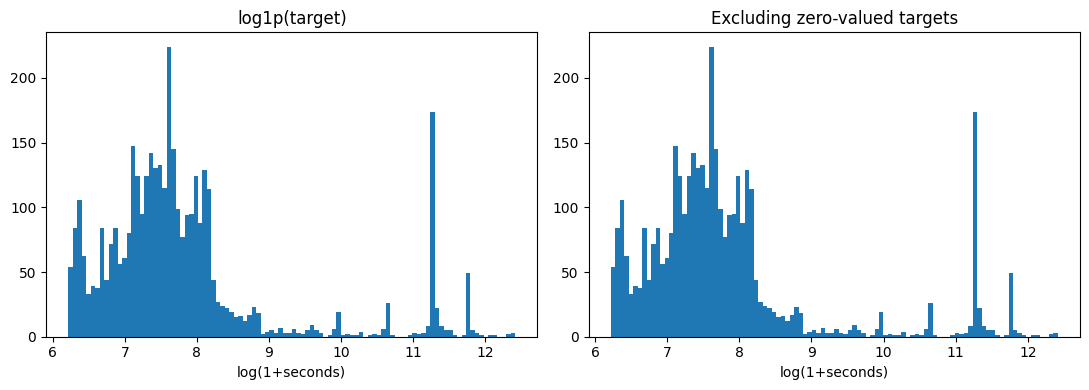

zero-valued targets: 0 / 3763


In [11]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(model_df['LOG_TARGET'], bins=100)
ax[0].set(title='log1p(target)', xlabel='log(1+seconds)')
ax[1].hist(model_df.loc[model_df['TARGET_VALUE'] > 0, 'LOG_TARGET'], bins=100)
ax[1].set(title='Excluding zero-valued targets', xlabel='log(1+seconds)')
plt.tight_layout(); save_fig('target_distribution'); plt.show()
print("zero-valued targets:", (model_df['TARGET_VALUE'] == 0).sum(), "/", len(model_df))

saved /kaggle/working/io_rate_vs_runtime_polaris_runtime.png


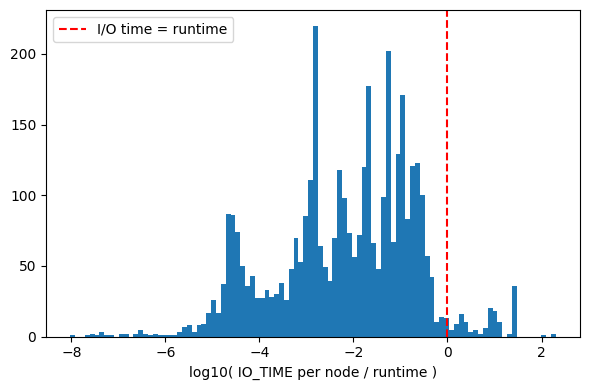

share of jobs with per-node I/O time > runtime: 0.04


In [12]:
r = (merged['IO_TIME'] / merged['NODES_REQUESTED']) / merged['RUNTIME_SECONDS']
r = r[np.isfinite(r) & (r > 0)]
plt.figure(figsize=(6, 4))
plt.hist(np.log10(r), bins=100); plt.axvline(0, color='red', ls='--', label='I/O time = runtime')
plt.xlabel('log10( IO_TIME per node / runtime )'); plt.legend(); plt.tight_layout(); save_fig('io_rate_vs_runtime'); plt.show()
print("share of jobs with per-node I/O time > runtime:", round(float((r > 1).mean()), 3))

saved /kaggle/working/backoff_level_polaris_runtime.png


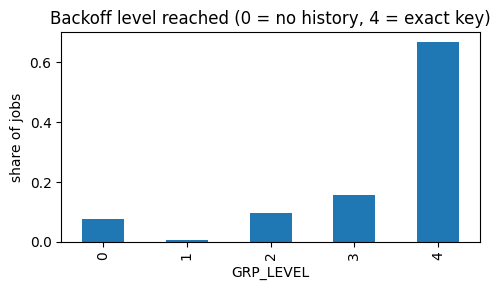

users: 79 | exact keys: 579 | exact key has >= 3 past jobs: 0.667
saved /kaggle/working/backoff_level_share_polaris_runtime.csv


/tmp/ipykernel_16/793289962.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  "| exact keys:", model_df.groupby(KEY4, dropna=False).ngroups,


,GRP_LEVEL,share_of_jobs
0,0,0.075472
1,1,0.004783
2,2,0.096997
3,3,0.155727
4,4,0.667021


In [13]:
cov = model_df['GRP_LEVEL'].value_counts(normalize=True).sort_index()
cov.plot(kind='bar', figsize=(5, 3), title='Backoff level reached (0 = no history, 4 = exact key)')
plt.ylabel('share of jobs'); plt.tight_layout(); save_fig('backoff_level'); plt.show()
print("users:", model_df['USERNAME_GENID'].nunique(),
      "| exact keys:", model_df.groupby(KEY4, dropna=False).ngroups,
      "| exact key has >= 3 past jobs:", (model_df['GRP_HIST_COUNT'] >= MIN_HIST).mean().round(3))
save_table(cov.rename('share_of_jobs').rename_axis('GRP_LEVEL').reset_index(), 'backoff_level_share')

saved /kaggle/working/history_vs_target_polaris_runtime.png


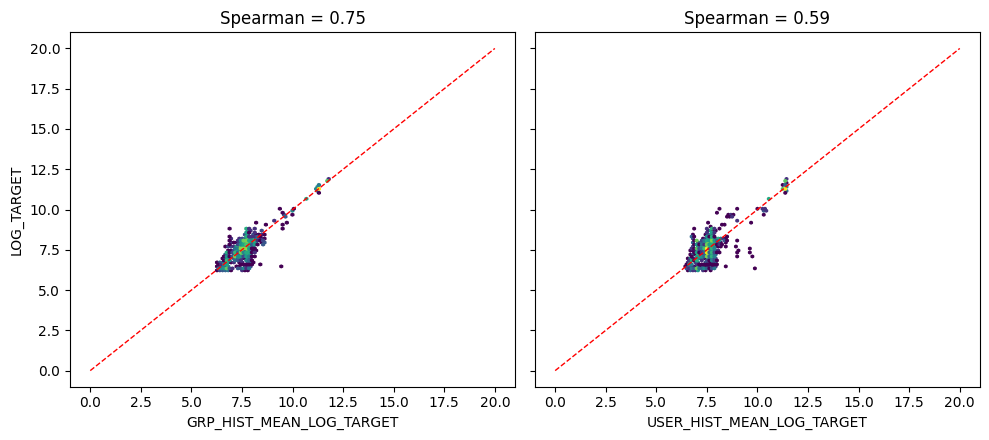

In [14]:
d = model_df[model_df['GRP_HIST_COUNT'] >= MIN_HIST]
fig, ax = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for a, c in zip(ax, ['GRP_HIST_MEAN_LOG_TARGET', 'USER_HIST_MEAN_LOG_TARGET']):
    a.hexbin(d[c], d['LOG_TARGET'], gridsize=40, bins='log', mincnt=1)
    a.plot([0, 20], [0, 20], 'r--', lw=1)
    a.set(xlabel=c, title=f"Spearman = {d[[c, 'LOG_TARGET']].corr(method='spearman').iloc[0, 1]:.2f}")
ax[0].set_ylabel('LOG_TARGET'); plt.tight_layout(); save_fig('history_vs_target'); plt.show()

saved /kaggle/working/weekly_trend_polaris_runtime.png


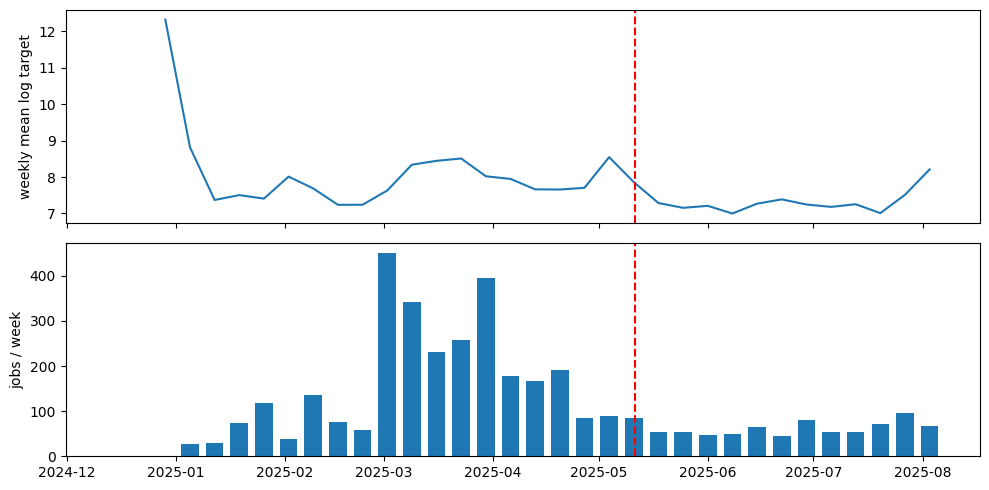

In [15]:
wk = model_df.set_index('QUEUED_TIMESTAMP')['LOG_TARGET'].resample('W').agg(['mean', 'count'])
fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(wk.index, wk['mean']); ax[0].set_ylabel('weekly mean log target')
ax[1].bar(wk.index, wk['count'], width=5); ax[1].set_ylabel('jobs / week')
for a in ax: a.axvline(split_date, color='red', ls='--')
plt.tight_layout(); save_fig('weekly_trend'); plt.show()

# Broad Model Comparison

In [16]:
def evaluate(y_true_log, y_pred_log, model_name, epsilon=1.0, verbose=True):
    y_pred_log = np.clip(y_pred_log, 0, 30)                  # the target cannot be negative
    y_true, y_pred = np.expm1(y_true_log), np.expm1(y_pred_log)
    mae_log = mean_absolute_error(y_true_log, y_pred_log)
    med_ae = median_absolute_error(y_true_log, y_pred_log)
    r2 = r2_score(y_true_log, y_pred_log)
    mdape = np.median(np.abs(y_pred - y_true) / (y_true + epsilon))
    within_2x = (np.abs(np.log2((y_pred + 1) / (y_true + 1))) <= 1).mean()
    if verbose:
        print(f"[{model_name}]  MAE(log)={mae_log:.4f}  MedAE(log)={med_ae:.4f}  R2(log)={r2:.4f}  "
              f"MdAPE={mdape:.2%}  within_2x={within_2x:.3f}")
    return dict(model=model_name, mae_log=mae_log, med_ae_log=med_ae, r2=r2, mdape=mdape, within_2x=within_2x)

In [17]:
NUM_LOG   = ['WALLTIME_SECONDS', 'NODES_REQUESTED', 'REQUESTED_CORE_HOURS']
LOW_CARD  = ['ALLOCATION_AWARD_CATEGORY', 'QUEUE_NAME', 'SCIENCE_FIELD_SHORT', 'MODE']
HIST_MEAN = ['GRP_HIST_MEAN_LOG_TARGET', 'GRP_HIST_LAST_LOG_TARGET', 'USER_HIST_MEAN_LOG_TARGET', 'EXE_HIST_MEAN_LOG_TARGET']
HIST_CNT  = ['GRP_HIST_COUNT', 'USER_HIST_COUNT', 'EXE_HIST_COUNT']
HIST_FLAG = ['GRP_LEVEL', 'EXE_IS_FIRST_OCCURRENCE', 'USER_IS_FIRST_OCCURRENCE']

In [18]:
def build_features(model_df, index):
    d = model_df.loc[index]                                   # model_df holds UNSCALED values
    gm = d['GLOBAL_MEAN_SO_FAR'].fillna(0.0)
    X = pd.DataFrame(index=d.index)
    for c in NUM_LOG:   X['LOG_' + c] = np.log1p(d[c].astype(float))
    for c in HIST_MEAN: X[c] = d[c].astype(float).fillna(gm)
    X['GRP_HIST_STD_LOG_TARGET'] = d['GRP_HIST_STD_LOG_TARGET'].astype(float).fillna(0.0)
    for c in HIST_CNT:  X['LOG_' + c] = np.log1p(d[c].astype(float).fillna(0.0))
    for c in HIST_FLAG: X[c] = d[c].astype(float)
    X['GRP_MINUS_USER'] = X['GRP_HIST_MEAN_LOG_TARGET'] - X['USER_HIST_MEAN_LOG_TARGET']
    X['LAST_MINUS_GRP'] = X['GRP_HIST_LAST_LOG_TARGET'] - X['GRP_HIST_MEAN_LOG_TARGET']
    for c in LOW_CARD:  X[c] = d[c].astype(str)
    base = X['GRP_HIST_MEAN_LOG_TARGET'].values.copy()            # used as the baseline for residual mode
    return X, base

In [19]:
def make_prep(kind, X):
    cat = LOW_CARD; num = [c for c in X.columns if c not in cat]
    if kind == 'scaled':                                      # linear / KNN / SVR
        return ColumnTransformer([('num', StandardScaler(), num),
                                  ('cat', OneHotEncoder(handle_unknown='ignore', min_frequency=20,
                                                        sparse_output=False), cat)])
    return ColumnTransformer([('num', 'passthrough', num),    # tree models: no scaling needed
                              ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat)])

In [20]:
def model_zoo(rs):
    return {
      'Ridge':       ('scaled', Ridge(random_state=rs), {'alpha': loguniform(1e-3, 1e3)}, 20),
      'Lasso':       ('scaled', Lasso(random_state=rs, max_iter=10000), {'alpha': loguniform(1e-4, 1)}, 20),
      'ElasticNet':  ('scaled', ElasticNet(random_state=rs, max_iter=10000),
                      {'alpha': loguniform(1e-4, 1), 'l1_ratio': uniform(0.1, 0.9)}, 20),
      'KNN':         ('scaled', KNeighborsRegressor(n_jobs=-1),
                      {'n_neighbors': randint(5, 60), 'weights': ['uniform', 'distance'], 'p': [1, 2]}, 20),
      'SVR':         ('scaled', SVR(kernel='rbf'),
                      {'C': loguniform(0.1, 100), 'gamma': loguniform(1e-4, 0.1), 'epsilon': uniform(0.01, 0.5)}, 15),
      'Random Forest': ('tree', RandomForestRegressor(random_state=rs, n_jobs=-1),
                      {'n_estimators': [200, 400], 'max_depth': [6, 10, 14, None],
                       'min_samples_leaf': randint(1, 30), 'max_features': [0.4, 0.6, 0.8, 1.0]}, 15),
      'Extra Trees': ('tree', ExtraTreesRegressor(random_state=rs, n_jobs=-1),
                      {'n_estimators': [200, 400], 'max_depth': [6, 10, 14, None],
                       'min_samples_leaf': randint(1, 30), 'max_features': [0.4, 0.6, 0.8, 1.0]}, 15),
      'HistGradientBoosting': ('tree', HistGradientBoostingRegressor(loss='absolute_error', random_state=rs),
                      {'learning_rate': loguniform(0.01, 0.2), 'max_depth': [3, 4, 5, 6, 8, None],
                       'min_samples_leaf': randint(10, 100), 'l2_regularization': loguniform(1e-3, 10),
                       'max_iter': [200, 400, 600]}, 25),
      'XGBoost':     ('tree', xgb.XGBRegressor(tree_method='hist', random_state=rs, n_jobs=-1),
                      {'objective': ['reg:absoluteerror', 'reg:pseudohubererror', 'reg:squarederror'],
                       'n_estimators': [200, 400, 600], 'max_depth': randint(2, 9),
                       'learning_rate': loguniform(0.01, 0.2), 'subsample': uniform(0.5, 0.5),
                       'colsample_bytree': uniform(0.5, 0.5), 'min_child_weight': randint(1, 50),
                       'reg_lambda': loguniform(1e-3, 10)}, 25),
    }

In [21]:
def run_broad(model_df, train_df, test_df, rs=42, modes=('direct', 'residual'), n_iter_scale=1.0, only=None):
    Xtr, btr = build_features(model_df, train_df.index)
    Xte, bte = build_features(model_df, test_df.index)
    ytr = train_df['LOG_TARGET'].values; yte = test_df['LOG_TARGET'].values
    rows, preds = [], {}
    baselines = [('Baseline: global train mean', np.full(len(yte), ytr.mean())),
                 ('Baseline: user history mean', Xte['USER_HIST_MEAN_LOG_TARGET'].values),
                 ('Baseline: group history mean', bte),
                 ('Baseline: group last value', Xte['GRP_HIST_LAST_LOG_TARGET'].values)]
    if TARGET == 'RUNTIME_SECONDS':                           # requested walltime, shifted to the runtime scale
        baselines.append(('Baseline: requested walltime (scaled)',
                          Xte['LOG_WALLTIME_SECONDS'].values + np.median(ytr - Xtr['LOG_WALLTIME_SECONDS'].values)))
    for name, p in baselines:
        rows.append({**evaluate(yte, p, name), 'mode': 'baseline', 'cv_mae': np.nan,
                     'train_time_sec': 0.0, 'params': {}})
    cv = TimeSeriesSplit(n_splits=3, gap=50)
    for mode in modes:
        off_tr = btr if mode == 'residual' else 0.0           # residual mode: learn y - group history mean
        off_te = bte if mode == 'residual' else 0.0
        for name, (kind, est, dist, n_iter) in model_zoo(rs).items():
            if only and name not in only: continue
            t0 = time.time()
            pipe = Pipeline([('prep', make_prep(kind, Xtr)), ('model', est)])
            search = RandomizedSearchCV(pipe, {f'model__{k}': v for k, v in dist.items()},
                                        n_iter=max(2, int(n_iter * n_iter_scale)), cv=cv,
                                        scoring='neg_mean_absolute_error', n_jobs=-1,
                                        random_state=rs, refit=True)
            search.fit(Xtr, ytr - off_tr)
            pred = search.predict(Xte) + off_te
            key = f'{name} [{mode}]'; preds[key] = pred
            rows.append({**evaluate(yte, pred, key), 'mode': mode, 'cv_mae': -search.best_score_,
                         'train_time_sec': time.time() - t0,
                         'params': {k.replace('model__', ''): v for k, v in search.best_params_.items()}})
    res = pd.DataFrame(rows)
    top = res[res['mode'] != 'baseline'].nsmallest(3, 'cv_mae')['model'].tolist()   # chosen on CV, not test
    if top:
        ens = np.mean([preds[m] for m in top], axis=0)
        res = pd.concat([res, pd.DataFrame([{**evaluate(yte, ens, 'Ensemble (top-3 by CV MAE)'),
                         'mode': 'ensemble', 'cv_mae': np.nan, 'train_time_sec': np.nan,
                         'params': {'members': top}}])], ignore_index=True)
    return res.sort_values('mae_log').reset_index(drop=True), preds

In [22]:
results_df, broad_preds = run_broad(model_df, train_df, test_df)
results_df.to_csv(f'/kaggle/working/broad_model_comparison_{TAG}.csv', index=False)
save_table(results_df[['model', 'mode', 'cv_mae', 'mae_log', 'med_ae_log', 'r2', 'within_2x', 'train_time_sec']], 'broad_model_table')
results_df[['model', 'mode', 'cv_mae', 'mae_log', 'med_ae_log', 'r2', 'within_2x', 'train_time_sec']]

[Baseline: global train mean]  MAE(log)=0.9322  MedAE(log)=0.8893  R2(log)=-0.4100  MdAPE=120.21%  within_2x=0.397
[Baseline: user history mean]  MAE(log)=0.5336  MedAE(log)=0.4107  R2(log)=0.4571  MdAPE=42.73%  within_2x=0.704
[Baseline: group history mean]  MAE(log)=0.4680  MedAE(log)=0.3411  R2(log)=0.4724  MdAPE=33.77%  within_2x=0.801
[Baseline: group last value]  MAE(log)=0.4943  MedAE(log)=0.3536  R2(log)=0.3836  MdAPE=31.74%  within_2x=0.736
[Baseline: requested walltime (scaled)]  MAE(log)=0.5271  MedAE(log)=0.4556  R2(log)=0.4718  MdAPE=40.08%  within_2x=0.688
[Ridge [direct]]  MAE(log)=0.4327  MedAE(log)=0.3493  R2(log)=0.6430  MdAPE=31.66%  within_2x=0.834
[Lasso [direct]]  MAE(log)=0.4314  MedAE(log)=0.3521  R2(log)=0.6443  MdAPE=31.99%  within_2x=0.837
[ElasticNet [direct]]  MAE(log)=0.4241  MedAE(log)=0.3406  R2(log)=0.6582  MdAPE=32.28%  within_2x=0.847
[KNN [direct]]  MAE(log)=0.4367  MedAE(log)=0.3195  R2(log)=0.6272  MdAPE=33.12%  within_2x=0.827
[SVR [direct]]  MAE(

,model,mode,cv_mae,mae_log,med_ae_log,r2,within_2x,train_time_sec
0,SVR [direct],direct,0.344084,0.391285,0.290139,0.680590,0.876494,4.016773
1,SVR [residual],residual,0.335005,0.394322,0.289619,0.659834,0.847278,3.879512
2,HistGradientBoosting [direct],direct,0.395165,0.397212,0.303886,0.685477,0.841965,26.881155
3,Ensemble (top-3 by CV MAE),ensemble,NaN,0.400186,0.289126,0.668497,0.848606,NaN
4,Extra Trees [direct],direct,0.380747,0.401240,0.342079,0.697136,0.855246,12.156826
5,XGBoost [direct],direct,0.414833,0.404129,0.310888,0.685870,0.848606,9.805692
6,Random Forest [direct],direct,0.384248,0.404327,0.318646,0.670264,0.836653,28.436909
7,Extra Trees [residual],residual,0.340849,0.409545,0.299865,0.665265,0.841965,12.309577
8,HistGradientBoosting [residual],residual,0.336323,0.414457,0.295957,0.640154,0.835325,26.637297
9,Random Forest [residual],residual,0.357021,0.421196,0.355378,0.635431,0.830013,33.860262


# Gradient Boosting Methods

In [23]:
def positional_folds(n, n_folds=5, min_train_frac=0.5, gap=50):
    edges = np.linspace(int(n * min_train_frac), n, n_folds + 1).astype(int)
    return [(np.arange(0, edges[i] - gap), np.arange(edges[i], edges[i + 1])) for i in range(n_folds)]

In [24]:
def prepare(model_df, train_df, test_df):
    assert train_df['QUEUED_TIMESTAMP'].is_monotonic_increasing, "train_df must be sorted by time"
    Xtr, btr = build_features(model_df, train_df.index); Xte, bte = build_features(model_df, test_df.index)
    d = dict(Xtr=Xtr, Xte=Xte, btr=btr, bte=bte, ytr=train_df['LOG_TARGET'].values, yte=test_df['LOG_TARGET'].values)
    d['ytr_res'] = d['ytr'] - btr                                   # residual target
    cats = {c: pd.Categorical(Xtr[c]).categories for c in LOW_CARD}
    def as_cat(X):
        X = X.copy()
        for c in LOW_CARD: X[c] = pd.Categorical(X[c], categories=cats[c])   # unseen levels -> NaN
        return X
    d['Xtr_cat'], d['Xte_cat'] = as_cat(Xtr), as_cat(Xte)
    enc = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1).fit(Xtr[LOW_CARD])
    def as_ord(X):
        X = X.copy(); X[LOW_CARD] = enc.transform(X[LOW_CARD]); return X
    d['Xtr_ord'], d['Xte_ord'] = as_ord(Xtr), as_ord(Xte)
    return d

In [25]:
SPECS = {}
def spec(name, frame):
    def deco(cls): SPECS[name] = (frame, cls); return cls
    return deco

@spec('LightGBM', 'cat')
class LGBSpec:
    @staticmethod
    def suggest(t):
        return dict(objective=t.suggest_categorical('objective', ['l1', 'huber', 'l2']),
                    learning_rate=t.suggest_float('learning_rate', 0.005, 0.2, log=True),
                    n_estimators=t.suggest_int('n_estimators', 100, 1200),
                    num_leaves=t.suggest_int('num_leaves', 7, 127), max_depth=t.suggest_int('max_depth', 3, 12),
                    min_child_samples=t.suggest_int('min_child_samples', 10, 200),
                    colsample_bytree=t.suggest_float('colsample_bytree', 0.5, 1.0),
                    subsample=t.suggest_float('subsample', 0.5, 1.0), subsample_freq=1,
                    reg_alpha=t.suggest_float('reg_alpha', 1e-4, 10, log=True),
                    reg_lambda=t.suggest_float('reg_lambda', 1e-4, 10, log=True),
                    min_split_gain=t.suggest_float('min_split_gain', 0.0, 1.0))
    @staticmethod
    def fit_predict(p, Xa, ya, Xb, seed):
        return lgb.LGBMRegressor(**p, random_state=seed, verbose=-1, n_jobs=-1).fit(Xa, ya).predict(Xb)

@spec('XGBoost', 'cat')
class XGBSpec:
    @staticmethod
    def suggest(t):
        return dict(objective=t.suggest_categorical('objective', ['reg:absoluteerror', 'reg:pseudohubererror', 'reg:squarederror']),
                    learning_rate=t.suggest_float('learning_rate', 0.005, 0.2, log=True),
                    n_estimators=t.suggest_int('n_estimators', 100, 1200), max_depth=t.suggest_int('max_depth', 2, 9),
                    min_child_weight=t.suggest_int('min_child_weight', 1, 100),
                    subsample=t.suggest_float('subsample', 0.5, 1.0), colsample_bytree=t.suggest_float('colsample_bytree', 0.5, 1.0),
                    reg_alpha=t.suggest_float('reg_alpha', 1e-4, 10, log=True),
                    reg_lambda=t.suggest_float('reg_lambda', 1e-4, 10, log=True), gamma=t.suggest_float('gamma', 1e-4, 5, log=True))
    @staticmethod
    def fit_predict(p, Xa, ya, Xb, seed):
        return xgb.XGBRegressor(**p, tree_method='hist', enable_categorical=True, random_state=seed, n_jobs=-1).fit(Xa, ya).predict(Xb)

@spec('CatBoost', 'raw')
class CBSpec:
    @staticmethod
    def suggest(t):
        return dict(loss_function=t.suggest_categorical('loss_function', ['MAE', 'Huber:delta=1.0', 'RMSE']),
                    learning_rate=t.suggest_float('learning_rate', 0.01, 0.3, log=True),
                    iterations=t.suggest_int('iterations', 100, 1000), depth=t.suggest_int('depth', 3, 9),
                    l2_leaf_reg=t.suggest_float('l2_leaf_reg', 1e-3, 30, log=True),
                    random_strength=t.suggest_float('random_strength', 1e-3, 10, log=True),
                    bagging_temperature=t.suggest_float('bagging_temperature', 0.0, 5.0))
    @staticmethod
    def fit_predict(p, Xa, ya, Xb, seed):
        return CatBoostRegressor(**p, cat_features=LOW_CARD, random_seed=seed, verbose=False, thread_count=-1).fit(Xa, ya).predict(Xb)

@spec('HistGradientBoosting', 'ord')
class HGBSpec:
    @staticmethod
    def suggest(t):
        return dict(loss=t.suggest_categorical('loss', ['absolute_error', 'squared_error']),
                    learning_rate=t.suggest_float('learning_rate', 0.005, 0.2, log=True),
                    max_iter=t.suggest_int('max_iter', 100, 1000), max_depth=t.suggest_int('max_depth', 2, 10),
                    min_samples_leaf=t.suggest_int('min_samples_leaf', 10, 150),
                    l2_regularization=t.suggest_float('l2_regularization', 1e-3, 10, log=True),
                    max_leaf_nodes=t.suggest_int('max_leaf_nodes', 8, 63))
    @staticmethod
    def fit_predict(p, Xa, ya, Xb, seed):
        return HistGradientBoostingRegressor(**p, random_state=seed).fit(Xa, ya).predict(Xb)

In [26]:
def run_boosting(model_df, train_df, test_df, n_trials=60, seeds=(0, 1, 2, 3, 4), n_folds=5, gap=50,
                 sampler_seed=42, only=None):
    D = prepare(model_df, train_df, test_df)
    folds = positional_folds(len(D['ytr']), n_folds=n_folds, gap=gap)
    rows, preds, studies = [], {}, {}
    for name, (frame, S) in SPECS.items():
        if only and name not in only: continue
        Xtr, Xte = {'cat': (D['Xtr_cat'], D['Xte_cat']), 'raw': (D['Xtr'], D['Xte']),
                    'ord': (D['Xtr_ord'], D['Xte_ord'])}[frame]
        def objective(trial):
            p = S.suggest(trial); errs = []
            for tr, va in folds:                                    # no early stopping: n_estimators is tuned
                pr = S.fit_predict(p, Xtr.iloc[tr], D['ytr_res'][tr], Xtr.iloc[va], seed=0) + D['btr'][va]
                errs.append(mean_absolute_error(D['ytr'][va], pr))
            return float(np.mean(errs))
        study = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=sampler_seed))
        study.optimize(objective, n_trials=n_trials); studies[name] = study
        best = S.suggest(optuna.trial.FixedTrial(study.best_params))
        pred = np.mean([S.fit_predict(best, Xtr, D['ytr_res'], Xte, seed=s) for s in seeds], axis=0) + D['bte']
        preds[name] = pred
        rows.append({**evaluate(D['yte'], pred, f'{name} (residual, tuned)'),
                     'cv_mae': study.best_value, 'params': study.best_params})
    res = pd.DataFrame(rows)
    return res, preds, studies, D

In [27]:
boost_df, boost_preds, boost_studies, D = run_boosting(model_df, train_df, test_df, n_trials=60)
boost_df.to_csv(f'/kaggle/working/boosting_model_comparison_{TAG}.csv', index=False)
save_table(boost_df[['model', 'cv_mae', 'mae_log', 'med_ae_log', 'r2', 'mdape', 'within_2x']], 'boosting_model_table')
boost_df[['model', 'cv_mae', 'mae_log', 'med_ae_log', 'r2', 'mdape', 'within_2x']]

[LightGBM (residual, tuned)]  MAE(log)=0.4527  MedAE(log)=0.3146  R2(log)=0.5355  MdAPE=31.45%  within_2x=0.815
[XGBoost (residual, tuned)]  MAE(log)=0.4258  MedAE(log)=0.3063  R2(log)=0.6072  MdAPE=31.42%  within_2x=0.830
[CatBoost (residual, tuned)]  MAE(log)=0.4089  MedAE(log)=0.3144  R2(log)=0.6589  MdAPE=31.33%  within_2x=0.841
[HistGradientBoosting (residual, tuned)]  MAE(log)=0.4280  MedAE(log)=0.3243  R2(log)=0.6351  MdAPE=32.84%  within_2x=0.829
saved /kaggle/working/boosting_model_table_polaris_runtime.csv


,model,cv_mae,mae_log,med_ae_log,r2,mdape,within_2x
0,"LightGBM (residual, tuned)",0.253893,0.452686,0.314587,0.535546,0.314479,0.815405
1,"XGBoost (residual, tuned)",0.247041,0.425754,0.306294,0.607221,0.314228,0.830013
2,"CatBoost (residual, tuned)",0.236263,0.408878,0.314422,0.658912,0.313323,0.840637
3,"HistGradientBoosting (residual, tuned)",0.267290,0.428012,0.324292,0.635101,0.328413,0.828685


# Clustering

In [28]:
CL_COLS = ['GRP_HIST_MEAN_LOG_TARGET', 'GRP_HIST_STD_LOG_TARGET', 'GRP_HIST_LAST_LOG_TARGET', 'USER_HIST_MEAN_LOG_TARGET',
           'EXE_HIST_MEAN_LOG_TARGET', 'LOG_WALLTIME_SECONDS', 'LOG_NODES_REQUESTED']

In [29]:
def kmeans_labels(D, k, seed=42):
    sc = StandardScaler().fit(D['Xtr'][CL_COLS])               # unsupervised: fitted on train features only
    km = KMeans(k, n_init=3, random_state=seed).fit(sc.transform(D['Xtr'][CL_COLS]))
    return km.labels_, km.predict(sc.transform(D['Xte'][CL_COLS]))

In [30]:
def fit_cluster_models(Z, yres, labels, alpha, min_size):
    models = {}
    for c in np.unique(labels):
        idx = np.where(labels == c)[0]
        if len(idx) >= min_size:                                  # smaller clusters get no model of their own
            models[c] = (Ridge(alpha=alpha).fit(Z[idx], yres[idx]), len(idx))
    return models

In [31]:
ZCOLS = ['LOG_WALLTIME_SECONDS', 'LOG_NODES_REQUESTED', 'GRP_HIST_STD_LOG_TARGET',
         'GRP_MINUS_USER', 'LAST_MINUS_GRP', 'LOG_GRP_HIST_COUNT']

In [32]:
def predict_with_cluster_models(models, Z, labels, base, global_pred, m):
    out = global_pred.copy(); served = np.zeros(len(Z), bool)
    for c, (mod, n) in models.items():
        idx = np.where(labels == c)[0]
        if len(idx) == 0: continue
        w = n / (n + m)                                           # big cluster -> trust its own model more
        out[idx] = (1 - w) * global_pred[idx] + w * (base[idx] + mod.predict(Z[idx]))
        served[idx] = True
    return out, served

In [33]:
def run_cluster_models(D, boost_studies, k_candidates, k_reference=(4,), alpha_grid=(1, 10, 100),
                       m_grid=(10, 30, 100), min_size=20, seeds=(0, 1, 2, 3, 4), n_folds=5, gap=50):
    S = SPECS['CatBoost'][1]
    params = S.suggest(optuna.trial.FixedTrial(boost_studies['CatBoost'].best_params))
    ytr, yres, btr = D['ytr'], D['ytr_res'], D['btr']; yte, bte = D['yte'], D['bte']
    zsc = StandardScaler().fit(D['Xtr'][ZCOLS]); Ztr = zsc.transform(D['Xtr'][ZCOLS]); Zte = zsc.transform(D['Xte'][ZCOLS])
    folds = positional_folds(len(ytr), n_folds=n_folds, gap=gap)
    gpred = [S.fit_predict(params, D['Xtr'].iloc[tr], yres[tr], D['Xtr'].iloc[va], 0) + btr[va] for tr, va in folds]
    cv_alone = np.mean([mean_absolute_error(ytr[va], p) for (tr, va), p in zip(folds, gpred)])
    rows, labs = [], {}
    for k in list(k_candidates) + list(k_reference):
        lab_tr, lab_te = kmeans_labels(D, k); labs[k] = (lab_tr, lab_te)
        for alpha in alpha_grid:
            errs = {m: [] for m in m_grid}
            for (tr, va), gp in zip(folds, gpred):
                models = fit_cluster_models(Ztr[tr], yres[tr], lab_tr[tr], alpha, min_size)
                for m in m_grid:
                    p, _ = predict_with_cluster_models(models, Ztr[va], lab_tr[va], btr[va], gp, m)
                    errs[m].append(mean_absolute_error(ytr[va], p))
            for m in m_grid:
                rows.append(dict(k=k, alpha=alpha, m=m, cv_mae=np.mean(errs[m]), ref=k in k_reference))
    cv_df = pd.DataFrame(rows).sort_values('cv_mae').reset_index(drop=True)
    
    pred_alone = np.mean([S.fit_predict(params, D['Xtr'], yres, D['Xte'], s) for s in seeds], axis=0) + bte
    out = [{**evaluate(yte, pred_alone, 'CatBoost alone (residual)'), 'cv_mae': cv_alone, 'k': None, 'alpha': None, 'm': None}]
    for ref_flag, tag in [(False, ''), (True, ' [reference]')]:
        sub = cv_df[cv_df.ref == ref_flag]
        if sub.empty: continue
        b = sub.iloc[0]; k, alpha, m = int(b.k), b.alpha, int(b.m); lab_tr, lab_te = labs[k]
        models = fit_cluster_models(Ztr, yres, lab_tr, alpha, min_size)
        p, served = predict_with_cluster_models(models, Zte, lab_te, bte, pred_alone, m)
        out.append({**evaluate(yte, p, f'Per-cluster Ridge + CatBoost (k={k}, alpha={alpha:g}, m={m}){tag}'),
                    'cv_mae': b.cv_mae, 'k': k, 'alpha': alpha, 'm': m})
        sizes = pd.Series(lab_tr).value_counts()
        print(f"[diagnostics{tag} k={k}] clusters: {len(sizes)} | with own model (>= {min_size} jobs): {len(models)} "
              f"| train size median {sizes.median():.0f}, min {sizes.min()}, max {sizes.max()} "
              f"| test jobs served by a cluster model: {served.mean():.3f}")
    return pd.DataFrame(out), cv_df

In [34]:
N_USERS = model_df['USERNAME_GENID'].nunique()

multiples  = {N_USERS * j for j in (1, 2, 3)}
equal_main = {int(k) for k in np.linspace(N_USERS, 3 * N_USERS, 8).round()}
K_CANDIDATES = sorted(multiples | equal_main)
equal_ref = {int(k) for k in np.linspace(1, N_USERS, 8).round()} - {N_USERS}
K_REFERENCE = tuple(sorted(equal_ref))

print(f"N_USERS = {N_USERS}")
print("main     :", K_CANDIDATES)
print("reference:", K_REFERENCE)

cluster_df, cluster_cv = run_cluster_models(D, boost_studies, K_CANDIDATES, k_reference=K_REFERENCE)
save_table(cluster_df, 'clustering_results')
save_table(cluster_cv, 'clustering_cv_grid')

N_USERS = 79
main     : [79, 102, 124, 147, 158, 169, 192, 214, 237]
reference: (1, 12, 23, 34, 46, 57, 68)
[CatBoost alone (residual)]  MAE(log)=0.4089  MedAE(log)=0.3144  R2(log)=0.6589  MdAPE=31.33%  within_2x=0.841
[Per-cluster Ridge + CatBoost (k=192, alpha=1, m=30)]  MAE(log)=0.4126  MedAE(log)=0.3108  R2(log)=0.6492  MdAPE=28.91%  within_2x=0.830
[diagnostics k=192] clusters: 192 | with own model (>= 20 jobs): 59 | train size median 8, min 1, max 118 | test jobs served by a cluster model: 0.527
[Per-cluster Ridge + CatBoost (k=46, alpha=1, m=100) [reference]]  MAE(log)=0.4098  MedAE(log)=0.3105  R2(log)=0.6596  MdAPE=31.00%  within_2x=0.829
[diagnostics [reference] k=46] clusters: 46 | with own model (>= 20 jobs): 36 | train size median 55, min 1, max 195 | test jobs served by a cluster model: 0.942
saved /kaggle/working/clustering_results_polaris_runtime.csv
saved /kaggle/working/clustering_cv_grid_polaris_runtime.csv


,k,alpha,m,cv_mae,ref
0,46,1,100,0.232020,True
1,46,10,100,0.234173,True
2,23,10,100,0.235182,True
3,68,10,100,0.235445,True
4,192,1,30,0.235563,False
...,...,...,...,...,...
139,1,100,10,0.345767,True
140,1,10,30,0.347979,True
141,1,1,30,0.348379,True
142,1,10,10,0.349559,True


      k    cv_mae  test_mae
0     1  0.339161  0.474497
1    12  0.260614  0.415639
2    23  0.235182  0.393583
3    34  0.237635  0.399818
4    46  0.232020  0.409837
5    57  0.236928  0.411147
6    68  0.235445  0.404394
7    79  0.235725  0.412563
8   102  0.236468  0.407848
9   124  0.235633  0.402483
10  147  0.236418  0.405376
11  158  0.236089  0.408750
12  169  0.236061  0.406480
13  192  0.235563  0.412626
14  214  0.235968  0.409648
15  237  0.235578  0.407112
saved /kaggle/working/cluster_k_curve_table_polaris_runtime.csv


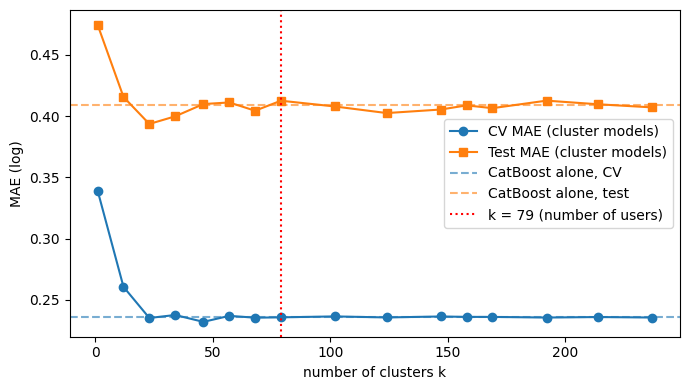

In [35]:
best_per_k = cluster_cv.sort_values('cv_mae').groupby('k').first().reset_index()
zsc = StandardScaler().fit(D['Xtr'][ZCOLS]); Ztr = zsc.transform(D['Xtr'][ZCOLS]); Zte = zsc.transform(D['Xte'][ZCOLS])
S = SPECS['CatBoost'][1]
params = S.suggest(optuna.trial.FixedTrial(boost_studies['CatBoost'].best_params))
pred_alone = np.mean([S.fit_predict(params, D['Xtr'], D['ytr_res'], D['Xte'], s) for s in (0, 1, 2, 3, 4)], axis=0) + D['bte']
curve = []
for _, r in best_per_k.iterrows():
    k = int(r.k); lab_tr, lab_te = kmeans_labels(D, k)
    models = fit_cluster_models(Ztr, D['ytr_res'], lab_tr, r.alpha, 20)
    p, _ = predict_with_cluster_models(models, Zte, lab_te, D['bte'], pred_alone, int(r.m))
    curve.append(dict(k=k, cv_mae=r.cv_mae, test_mae=mean_absolute_error(D['yte'], p)))
curve = pd.DataFrame(curve)
print(curve)
save_table(curve, 'cluster_k_curve_table')

curve['cv_alone'] = cluster_df.loc[0, 'cv_mae']
plt.figure(figsize=(7, 4))
plt.plot(curve.k, curve.cv_mae, marker='o', label='CV MAE (cluster models)')
plt.plot(curve.k, curve.test_mae, marker='s', label='Test MAE (cluster models)')
plt.axhline(cluster_df.loc[0, 'cv_mae'], color='C0', ls='--', alpha=.6, label='CatBoost alone, CV')
plt.axhline(cluster_df.loc[0, 'mae_log'], color='C1', ls='--', alpha=.6, label='CatBoost alone, test')
plt.axvline(N_USERS, color='red', ls=':', label=f'k = {N_USERS} (number of users)')
plt.xlabel('number of clusters k'); plt.ylabel('MAE (log)'); plt.legend(); plt.tight_layout()
plt.savefig(f'/kaggle/working/cluster_k_curve_{TAG}.png', dpi=150); plt.show()

In [36]:
K_SHOW = int(cluster_cv[~cluster_cv['ref']].iloc[0]['k'])      # k chosen by CV (or set e.g. K_SHOW = N_USERS)
lab_tr, lab_te = kmeans_labels(D, K_SHOW)                       # same seed -> same clusters the pipeline used

tr_ids = model_df.loc[train_df.index, 'COBALT_JOBID'].values
te_ids = model_df.loc[test_df.index,  'COBALT_JOBID'].values

rows = []
for c in sorted(set(lab_tr) | set(lab_te)):
    tr, te = tr_ids[lab_tr == c], te_ids[lab_te == c]
    rows.append(dict(cluster=c, n_train=len(tr), n_test=len(te),
                     train_job_ids=' '.join(map(str, tr)), test_job_ids=' '.join(map(str, te))))
table = pd.DataFrame(rows)
table.to_csv(f'{OUT}/cluster_jobids_k{K_SHOW}_{TAG}.csv', index=False)
print(table.drop(columns=['train_job_ids', 'test_job_ids']).head(5).to_string(index=False))

 cluster  n_train  n_test
       0       91       0
       1       23       0
       2       32       9
       3       27       6
       4        1       0


# Job Co-Scheduling and Contention

In [37]:
# Jobs running at the moment each job is queued (known at prediction time).
interval_df = jobcomp_theta[['COBALT_JOBID', 'START_TIMESTAMP', 'END_TIMESTAMP', 'NODES_REQUESTED']].copy()
interval_df['START_TIMESTAMP'] = pd.to_datetime(interval_df['START_TIMESTAMP'])
interval_df['END_TIMESTAMP']   = pd.to_datetime(interval_df['END_TIMESTAMP'])
interval_df = interval_df.dropna(subset=['START_TIMESTAMP', 'END_TIMESTAMP'])
interval_df = interval_df[interval_df['END_TIMESTAMP'] > interval_df['START_TIMESTAMP']]

# Each running job's expected target value = its own history-based estimate (never its actual target value)
interval_df = (interval_df.drop(columns=['EXE_HIST_MEAN_LOG_TARGET'], errors='ignore')
               .merge(model_df[['COBALT_JOBID', 'EXE_HIST_MEAN_LOG_TARGET']], on='COBALT_JOBID', how='left'))
interval_df['EXE_HIST_MEAN_LOG_TARGET'] = interval_df['EXE_HIST_MEAN_LOG_TARGET'].fillna(train_df['LOG_TARGET'].mean())

In [38]:
def contention_at(interval_df, query_times):
    s = interval_df.sort_values('START_TIMESTAMP')
    e = interval_df.sort_values('END_TIMESTAMP')
    s_t, e_t = s['START_TIMESTAMP'].values, e['END_TIMESTAMP'].values
    s_n, s_h = s['NODES_REQUESTED'].values.astype(float), s['EXE_HIST_MEAN_LOG_TARGET'].values
    e_n, e_h = e['NODES_REQUESTED'].values.astype(float), e['EXE_HIST_MEAN_LOG_TARGET'].values
    cs_n, cs_h = np.cumsum(s_n), np.cumsum(s_h)
    ce_n, ce_h = np.cumsum(e_n), np.cumsum(e_h)
    q = pd.to_datetime(query_times).values
    i = np.searchsorted(s_t, q, side='right')            # jobs started by q
    j = np.searchsorted(e_t, q, side='right')            # jobs ended by q
    def cum(c, k): return np.where(k > 0, c[np.maximum(k - 1, 0)], 0.0)
    n_run     = i - j
    nodes_run = cum(cs_n, i) - cum(ce_n, j)
    target_run    = cum(cs_h, i) - cum(ce_h, j)
    return pd.DataFrame({'SUBMIT_N_CONCURRENT': n_run,
                         'SUBMIT_CONCURRENT_NODES': nodes_run,
                         'SUBMIT_CONCURRENT_TARGET': np.where(n_run > 0, target_run / np.maximum(n_run, 1), 0.0)},
                        index=model_df.index)

In [39]:
CONT_COLS = ['SUBMIT_N_CONCURRENT', 'SUBMIT_CONCURRENT_NODES', 'SUBMIT_CONCURRENT_TARGET']
model_df = model_df.drop(columns=[c for c in CONT_COLS if c in model_df.columns])
model_df = model_df.join(contention_at(interval_df, model_df['QUEUED_TIMESTAMP']))
model_df[CONT_COLS].describe()

,SUBMIT_N_CONCURRENT,SUBMIT_CONCURRENT_NODES,SUBMIT_CONCURRENT_TARGET
count,3763.000000,3763.000000,3763.000000
mean,50.593410,525.728142,7.930045
std,11.218315,62.610168,0.131769
min,0.000000,0.000000,0.000000
25%,44.000000,529.000000,7.929822
50%,51.000000,543.000000,7.945163
75%,57.000000,551.000000,7.947166
max,122.000000,587.000000,7.953424


In [40]:
CB   = SPECS['CatBoost'][1]
best = CB.suggest(optuna.trial.FixedTrial(boost_studies['CatBoost'].best_params))   # tuned on the baseline features
folds = positional_folds(len(D['ytr']), n_folds=5, gap=50)
seeds = (0, 1, 2, 3, 4)

In [41]:
def cv_and_test(Xtr, Xte):
    cv = []
    for tr, va in folds:
        p = np.mean([CB.fit_predict(best, Xtr.iloc[tr], D['ytr_res'][tr], Xtr.iloc[va], s) for s in seeds], axis=0)
        cv.append(mean_absolute_error(D['ytr'][va], p + D['btr'][va]))
    p = np.mean([CB.fit_predict(best, Xtr, D['ytr_res'], Xte, s) for s in seeds], axis=0) + D['bte']
    return float(np.mean(cv)), p

In [42]:
Xtr_c = D['Xtr'].join(model_df.loc[D['Xtr'].index, CONT_COLS])
Xte_c = D['Xte'].join(model_df.loc[D['Xte'].index, CONT_COLS])

rows = []
for label, (Xa, Xb) in {'CatBoost, history features': (D['Xtr'], D['Xte']),
                        'CatBoost + contention features': (Xtr_c, Xte_c)}.items():
    cv, pred = cv_and_test(Xa, Xb)
    rows.append({**evaluate(D['yte'], pred, label), 'cv_mae': cv})

contention_df = pd.DataFrame(rows)
contention_df.to_csv(f'/kaggle/working/contention_ablation_{TAG}.csv', index=False)
save_table(contention_df[['model', 'cv_mae', 'mae_log', 'med_ae_log', 'r2', 'mdape', 'within_2x']], 'contention_ablation_table')
contention_df[['model', 'cv_mae', 'mae_log', 'med_ae_log', 'r2', 'mdape', 'within_2x']]

[CatBoost, history features]  MAE(log)=0.4089  MedAE(log)=0.3144  R2(log)=0.6589  MdAPE=31.33%  within_2x=0.841
[CatBoost + contention features]  MAE(log)=0.4077  MedAE(log)=0.3028  R2(log)=0.6586  MdAPE=29.81%  within_2x=0.837
saved /kaggle/working/contention_ablation_table_polaris_runtime.csv


,model,cv_mae,mae_log,med_ae_log,r2,mdape,within_2x
0,"CatBoost, history features",0.238184,0.408878,0.314422,0.658912,0.313323,0.840637
1,CatBoost + contention features,0.253437,0.407671,0.302774,0.658643,0.298064,0.836653


# Error Analysis

In [43]:
cols = ['QUEUED_TIMESTAMP', 'GRP_LEVEL', 'NODES_REQUESTED', 'USERNAME_GENID']
err = model_df.loc[test_df.index, cols].copy()
err['y']       = D['yte']                       # actual LOG_TARGET
err['pred']    = boost_preds['CatBoost']        # same order as test_df
err['abs_err'] = (err['y'] - err['pred']).abs()
err['bias']    = err['pred'] - err['y']         # > 0 means over-prediction
err['zero_target'] = err['y'] == 0

In [44]:
def summarize(g):
    return pd.Series({'n_jobs': len(g),
                      'share_jobs': len(g) / len(err),
                      'MAE': g['abs_err'].mean(),
                      'MedAE': g['abs_err'].median(),
                      'bias': g['bias'].mean(),
                      'share_of_total_error': g['abs_err'].sum() / err['abs_err'].sum()})

In [45]:
print('Overall: MAE %.4f  MedAE %.4f  bias %+.4f' %
      (err['abs_err'].mean(), err['abs_err'].median(), err['bias'].mean()))

Overall: MAE 0.4089  MedAE 0.3144  bias +0.0084


           n_jobs  share_jobs    MAE  MedAE   bias  share_of_total_error
GRP_LEVEL                                                               
0            48.0       0.064  0.702  0.567 -0.197                 0.110
1             9.0       0.012  0.530  0.430 -0.112                 0.015
2           102.0       0.135  0.579  0.439  0.176                 0.192
3           285.0       0.378  0.350  0.293  0.038                 0.324
4           309.0       0.410  0.358  0.290 -0.039                 0.359
             n_jobs  share_jobs    MAE  MedAE   bias  share_of_total_error
zero_target                                                               
False         753.0         1.0  0.409  0.314  0.008                   1.0
                  n_jobs  share_jobs    MAE  MedAE   bias  \
QUEUED_TIMESTAMP                                            
2025-05-11          19.0       0.025  0.306  0.218 -0.120   
2025-05-18          53.0       0.070  0.399  0.339 -0.131   
2025-05-25          

/tmp/ipykernel_16/16248405.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_level = err.groupby('GRP_LEVEL').apply(summarize)
/tmp/ipykernel_16/16248405.py:6: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_zero = err.groupby('zero_target').apply(summarize)


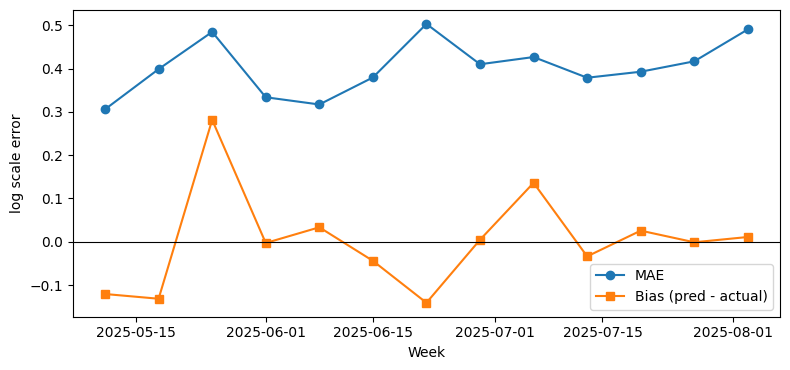

              n_jobs  share_jobs    MAE  MedAE   bias  share_of_total_error
size_bin                                                                   
(0.999, 2.0]   524.0       0.696  0.370  0.301 -0.024                 0.629
(2.0, 4.0]      72.0       0.096  0.497  0.372  0.012                 0.116
(4.0, 128.0]   157.0       0.208  0.499  0.331  0.116                 0.254
                n_jobs  share_jobs    MAE  MedAE   bias  share_of_total_error
USERNAME_GENID                                                               
40563830007130   282.0       0.375  0.309  0.296 -0.049                 0.283
4659796787733     90.0       0.120  0.407  0.331  0.007                 0.119
99113075388182    20.0       0.027  0.815  0.668  0.284                 0.053
7306616244514     24.0       0.032  0.606  0.441  0.001                 0.047
56556059632709    30.0       0.040  0.427  0.403 -0.012                 0.042
15604816617260     7.0       0.009  1.666  1.537 -0.549                 0.

/tmp/ipykernel_16/16248405.py:26: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  by_size = err.groupby('size_bin', observed=True).apply(summarize)
/tmp/ipykernel_16/16248405.py:30: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  by_user = err.groupby('USERNAME_GENID').apply(summarize).sort_values('share_of_total_error', ascending=False)
/tmp/ipykernel_16/16248405.py:30: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping 

,n_jobs,share_jobs,MAE,MedAE,bias,share_of_total_error
USERNAME_GENID,,,,,,
40563830007130,282.0,0.374502,0.309217,0.295945,-0.049406,0.283220
4659796787733,90.0,0.119522,0.407452,0.331041,0.007154,0.119105
99113075388182,20.0,0.026560,0.815064,0.667821,0.284412,0.052946
7306616244514,24.0,0.031873,0.605695,0.441449,0.001012,0.047215
56556059632709,30.0,0.039841,0.427359,0.402502,-0.012383,0.041641
15604816617260,7.0,0.009296,1.665885,1.536800,-0.549000,0.037875
39835015470085,35.0,0.046481,0.327322,0.231990,-0.021530,0.037210
27038119373395,25.0,0.033201,0.448606,0.366903,0.008322,0.036426
33656384019952,8.0,0.010624,1.274376,1.630896,1.224513,0.033113


In [46]:
# 1. By history level (how much history the group had)
by_level = err.groupby('GRP_LEVEL').apply(summarize)
print(by_level.round(3))

# 2. Zero-valued targets vs the rest
by_zero = err.groupby('zero_target').apply(summarize)
print(by_zero.round(3))

# 3. Over time inside the test period (weekly)
_wk = err.groupby(pd.Grouper(key='QUEUED_TIMESTAMP', freq='W'))
by_week = pd.DataFrame({k: summarize(g) for k, g in _wk if len(g)}).T       # skips empty weeks (e.g. a gap in the log)
by_week.index.name = 'QUEUED_TIMESTAMP'
print(by_week.round(3))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(by_week.index, by_week['MAE'], marker='o', label='MAE')
ax.plot(by_week.index, by_week['bias'], marker='s', label='Bias (pred - actual)')
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('log scale error'); ax.set_xlabel('Week'); ax.legend()
plt.tight_layout()
plt.savefig(f'/kaggle/working/error_over_time_{TAG}.png', dpi=150)
plt.show()

# 4. By job size (requested nodes, quartiles of the test set)
err['size_bin'] = pd.qcut(err['NODES_REQUESTED'], q=4, duplicates='drop')
by_size = err.groupby('size_bin', observed=True).apply(summarize)
print(by_size.round(3))

# 5. By user: how concentrated is the error?
by_user = err.groupby('USERNAME_GENID').apply(summarize).sort_values('share_of_total_error', ascending=False)
print(by_user.head(10).round(3))
print('Top 10 users: %.1f%% of total error' % (100 * by_user['share_of_total_error'].head(10).sum()))

# 6. How much comes from the worst jobs?
cut = err['abs_err'].quantile(0.95)
print('Worst 5%% of jobs: %.1f%% of total error' % (100 * err.loc[err['abs_err'] >= cut, 'abs_err'].sum() / err['abs_err'].sum()))

# save everything for the write-up
with pd.ExcelWriter(f'/kaggle/working/error_analysis_{TAG}.xlsx') as w:
    by_level.to_excel(w, 'by_level'); by_zero.to_excel(w, 'zero_target')
    by_week.to_excel(w, 'by_week');   by_size.to_excel(w, 'by_size')
    by_user.head(20).to_excel(w, 'top_users')
save_table(by_level, 'error_by_level', index=True); save_table(by_zero, 'error_by_zero_target', index=True)
save_table(by_week, 'error_by_week', index=True);   save_table(by_size, 'error_by_size', index=True)
save_table(by_user.head(10), 'error_top_users', index=True)

# Diagnostic Cells

In [47]:
lvl  = model_df.loc[test_df.index, 'GRP_LEVEL']                 # history level of each test job (4 = exact key has history)
succ = jobcomp_theta[(jobcomp_theta['EXIT_STATUS'] == 0) & (jobcomp_theta['EXIT_CODE'] == 0)]
raw  = model_df['TARGET_VALUE']                                       # holds the selected TARGET
summary = pd.Series(dict(
    machine=MACHINE, target=TARGET, n_jobs=len(model_df), n_users=model_df['USERNAME_GENID'].nunique(),
    n_exact_keys=model_df.groupby(KEY4, observed=True, dropna=False).ngroups, n_exe_ids=model_df['EXE_NAME_GENID'].nunique(),
    darshan_coverage=len(merged) / len(succ), test_days=(model_df['QUEUED_TIMESTAMP'].max() - split_date).days,
    test_share_level4=(lvl == 4).mean(), test_share_level0=(lvl == 0).mean(),
    target_p05=raw.quantile(.05), target_p50=raw.median(), target_p95=raw.quantile(.95), share_target_lt_1s=(raw < 1).mean(),
    spearman_io_vs_runtime=merged[['IO_TIME', 'RUNTIME_SECONDS']].corr(method='spearman').iloc[0, 1],
    test_mae_catboost=mean_absolute_error(D['yte'], boost_preds['CatBoost'])))
print(summary.to_string())
save_table(summary.to_frame().T, 'summary')

# Darshan coverage by month (the history features only see jobs that have a Darshan record)
s = succ.assign(m=pd.to_datetime(succ['QUEUED_TIMESTAMP']).dt.to_period('M'))
cov = pd.DataFrame({'all_jobs': s.groupby('m').size(), 'with_darshan': merged.groupby(merged['QUEUED_TIMESTAMP'].dt.to_period('M')).size()}).fillna(0).astype(int)
cov['share'] = cov['with_darshan'] / cov['all_jobs']
print(); print(cov.round(3).to_string())

machine                           polaris
target                    RUNTIME_SECONDS
n_jobs                               3763
n_users                                79
n_exact_keys                          579
n_exe_ids                               1
darshan_coverage                 0.026883
test_days                              81
test_share_level4                0.410359
test_share_level0                0.063745
target_p05                          586.1
target_p50                         1933.0
target_p95                        79512.1
share_target_lt_1s                    0.0
spearman_io_vs_runtime           0.153343
test_mae_catboost                0.408878
saved /kaggle/working/summary_polaris_runtime.csv

         all_jobs  with_darshan  share
2024-12        57             8  0.140
2025-01      5783           273  0.047
2025-02      8187           641  0.078
2025-03     14178          1360  0.096
2025-04     14960           619  0.041
2025-05      7687           273  0.036
2025

In [48]:
num = [c for c in D['Xtr'].columns if c not in LOW_CARD]
Xa, Xb, ya, yb = D['Xtr'][num], D['Xte'][num], D['ytr'], D['yte']

def ridge_mae(cols):
    m = Pipeline([('sc', StandardScaler()), ('r', Ridge(alpha=1.0))]).fit(Xa[cols], ya)
    return mean_absolute_error(yb, np.clip(m.predict(Xb[cols]), 0, 30))

full = ridge_mae(num)
loo  = pd.Series({c: ridge_mae([k for k in num if k != c]) - full for c in num}).sort_values(ascending=False)
print(f'Ridge test MAE, all features: {full:.4f}')
print('MAE increase when ONE feature is removed (a big jump = that feature carries the result):')
print(loo.head(5).round(4).to_string())

# REQUESTED_CORE_HOURS: is it computed from the requested walltime or from the actual runtime?
chk = merged[['REQUESTED_CORE_HOURS', 'CORES_REQUESTED', 'WALLTIME_SECONDS', 'RUNTIME_SECONDS']].astype(float)
chk = chk[(chk > 0).all(axis=1)]
implied = chk['REQUESTED_CORE_HOURS'] * 3600 / chk['CORES_REQUESTED']
for ref in ['WALLTIME_SECONDS', 'RUNTIME_SECONDS']:
    lr = np.log(implied / chk[ref])
    print(f'implied seconds vs {ref}: median ratio {np.exp(lr.median()):.3f}, spread {lr.std():.3f}   (spread ~0 = computed from this)')

Ridge test MAE, all features: 0.4427
MAE increase when ONE feature is removed (a big jump = that feature carries the result):
EXE_HIST_MEAN_LOG_TARGET    0.0131
EXE_IS_FIRST_OCCURRENCE     0.0065
LOG_EXE_HIST_COUNT          0.0057
LOG_WALLTIME_SECONDS        0.0004
GRP_HIST_LAST_LOG_TARGET    0.0000
implied seconds vs WALLTIME_SECONDS: median ratio 1.000, spread 0.000   (spread ~0 = computed from this)
implied seconds vs RUNTIME_SECONDS: median ratio 2.691, spread 0.666   (spread ~0 = computed from this)


In [49]:
y_all = model_df['LOG_TARGET']
rows = []
for name, keys in LEVELS.items():
    g = model_df.groupby(keys, observed=True, dropna=False)['LOG_TARGET']
    n, s = g.transform('size'), g.transform('sum')
    ok = n >= 4
    e = y_all[ok] - (s - y_all)[ok] / (n[ok] - 1)               # error of predicting a job by the mean of the OTHER jobs in its group
    rows.append(dict(level=name, coverage=ok.mean(), peer_MAE=e.abs().mean()))
ceiling = pd.DataFrame(rows)
print(ceiling.round(3).to_string(index=False))
print(f"model test MAE: {mean_absolute_error(D['yte'], boost_preds['CatBoost']):.3f}   (peer_MAE = the best a history-only method could do, roughly)")
save_table(ceiling, 'noise_ceiling')

pred = np.asarray(boost_preds['CatBoost'])
tb = (pd.DataFrame({'true_seconds': pd.cut(np.expm1(D['yte']), [-np.inf, 1, 10, 100, 1e3, 1e4, 1e5, np.inf]),
                    'abs_err': np.abs(D['yte'] - pred)})
        .groupby('true_seconds', observed=True)['abs_err'].agg(n='size', MAE='mean'))
print('\nTest error by size of the TRUE target:'); print(tb.round(3).to_string())

level  coverage  peer_MAE
   G4     0.837     0.250
   G3     0.938     0.317
   G2     0.986     0.418
   G1     0.989     0.419
model test MAE: 0.409   (peer_MAE = the best a history-only method could do, roughly)
saved /kaggle/working/noise_ceiling_polaris_runtime.csv

Test error by size of the TRUE target:
                       n    MAE
true_seconds                   
(100.0, 1000.0]      294  0.429
(1000.0, 10000.0]    421  0.370
(10000.0, 100000.0]   36  0.659
(100000.0, inf]        2  1.158


In [50]:
CB = SPECS['CatBoost'][1]
best_cb = CB.suggest(optuna.trial.FixedTrial(boost_studies['CatBoost'].best_params))
ALLF = list(D['Xtr'].columns)
GROUPS = {
    'size (walltime/nodes/core-hours)': ['LOG_WALLTIME_SECONDS', 'LOG_NODES_REQUESTED', 'LOG_REQUESTED_CORE_HOURS'],
    'core-hours only':                  ['LOG_REQUESTED_CORE_HOURS'],
    'group history':                    ['GRP_HIST_MEAN_LOG_TARGET', 'GRP_HIST_LAST_LOG_TARGET', 'GRP_HIST_STD_LOG_TARGET',
                                         'LOG_GRP_HIST_COUNT', 'GRP_LEVEL', 'GRP_MINUS_USER', 'LAST_MINUS_GRP'],
    'user history':                     ['USER_HIST_MEAN_LOG_TARGET', 'LOG_USER_HIST_COUNT', 'USER_IS_FIRST_OCCURRENCE'],
    'executable history':               ['EXE_HIST_MEAN_LOG_TARGET', 'LOG_EXE_HIST_COUNT', 'EXE_IS_FIRST_OCCURRENCE'],
    'categoricals':                     LOW_CARD,
}
def cb_mae(cols):
    cats = [c for c in LOW_CARD if c in cols]
    p = np.mean([CatBoostRegressor(**best_cb, cat_features=cats, random_seed=s, verbose=False, thread_count=-1)
                 .fit(D['Xtr'][cols], D['ytr']).predict(D['Xte'][cols]) for s in (0, 1)], axis=0)
    return mean_absolute_error(D['yte'], np.clip(p, 0, 30))
base = cb_mae(ALLF)
rows = [dict(setup='ALL features', test_mae=base, change=0.0)]
for g, cols in GROUPS.items():
    m = cb_mae([c for c in ALLF if c not in cols]); rows.append(dict(setup=f'without {g}', test_mae=m, change=m - base))
for g, cols in GROUPS.items():
    m = cb_mae(cols); rows.append(dict(setup=f'ONLY {g}', test_mae=m, change=m - base))
ablation = pd.DataFrame(rows)
print(ablation.round(4).to_string(index=False))
save_table(ablation, 'group_ablation')

                                   setup  test_mae  change
                            ALL features    0.4096  0.0000
without size (walltime/nodes/core-hours)    0.4488  0.0392
                 without core-hours only    0.4188  0.0092
                   without group history    0.4643  0.0547
                    without user history    0.4351  0.0256
              without executable history    0.4104  0.0008
                    without categoricals    0.4176  0.0080
   ONLY size (walltime/nodes/core-hours)    0.5196  0.1100
                    ONLY core-hours only    0.5599  0.1503
                      ONLY group history    0.4846  0.0750
                       ONLY user history    0.5593  0.1498
                 ONLY executable history    3.0402  2.6306
                       ONLY categoricals    0.6127  0.2031
saved /kaggle/working/group_ablation_polaris_runtime.csv


,setup,test_mae,change
0,ALL features,0.409591,0.000000
1,without size (walltime/nodes/core-hours),0.448788,0.039197
2,without core-hours only,0.418795,0.009204
3,without group history,0.464290,0.054699
4,without user history,0.435147,0.025555
5,without executable history,0.410383,0.000791
6,without categoricals,0.417614,0.008023
7,ONLY size (walltime/nodes/core-hours),0.519585,0.109993
8,ONLY core-hours only,0.559880,0.150289
9,ONLY group history,0.484624,0.075032


In [51]:
from scipy.stats import ks_2samp
A, B = D['Xtr'][num], D['Xte'][num]
shift = pd.DataFrame([dict(feature=c, ks=ks_2samp(A[c], B[c]).statistic,
                           test_outside_train_range=((B[c] < A[c].min()) | (B[c] > A[c].max())).mean(),
                           train_mean=A[c].mean(), test_mean=B[c].mean()) for c in num]).sort_values('ks', ascending=False)
print(shift.head(8).round(3).to_string(index=False))
print('\ntarget (log), train vs test:')
print(pd.DataFrame({'train': pd.Series(D['ytr']).describe(), 'test': pd.Series(D['yte']).describe()}).round(3).to_string())
save_table(shift, 'feature_shift')

                  feature    ks  test_outside_train_range  train_mean  test_mean
       LOG_EXE_HIST_COUNT 1.000                     0.996       6.969      8.124
     LOG_WALLTIME_SECONDS 0.518                     0.000       8.982      8.251
 EXE_HIST_MEAN_LOG_TARGET 0.496                     0.000       7.775      7.868
 LOG_REQUESTED_CORE_HOURS 0.449                     0.000       6.515      5.182
       LOG_GRP_HIST_COUNT 0.394                     0.000       2.657      1.347
USER_HIST_MEAN_LOG_TARGET 0.369                     0.000       7.875      7.467
      LOG_NODES_REQUESTED 0.355                     0.000       1.860      1.401
  GRP_HIST_STD_LOG_TARGET 0.341                     0.000       0.268      0.404

target (log), train vs test:
          train     test
count  3010.000  753.000
mean      7.947    7.334
std       1.322    0.958
min       6.219    6.230
25%       7.192    6.706
50%       7.623    7.158
75%       8.101    7.784
max      12.415   11.770
saved /kaggle/wo

,feature,ks,test_outside_train_range,train_mean,test_mean
10,LOG_EXE_HIST_COUNT,0.999668,0.996016,6.969100,8.123595
0,LOG_WALLTIME_SECONDS,0.517686,0.000000,8.982025,8.251268
6,EXE_HIST_MEAN_LOG_TARGET,0.496013,0.000000,7.774884,7.868191
2,LOG_REQUESTED_CORE_HOURS,0.448963,0.000000,6.514971,5.182384
8,LOG_GRP_HIST_COUNT,0.394478,0.000000,2.657450,1.347153
5,USER_HIST_MEAN_LOG_TARGET,0.369339,0.000000,7.875427,7.466739
1,LOG_NODES_REQUESTED,0.355288,0.000000,1.859986,1.400602
7,GRP_HIST_STD_LOG_TARGET,0.341099,0.000000,0.267866,0.403693
11,GRP_LEVEL,0.320871,0.000000,3.402658,3.059761
4,GRP_HIST_LAST_LOG_TARGET,0.291314,0.000000,7.959862,7.353663


In [52]:
zip_outputs()

zipped -> /kaggle/working/outputs_polaris_runtime.zip
